# Brain MRI Tumor Segmentation - Final Showcase
Welcome to the final results of the Brain MRI Segmentation ensemble model! This notebook will load the trained models, evaluate them on the unseen test set, and visualize Explainable AI (XAI) heatmaps.

In [1]:
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Ensure the src module can be imported
sys.path.append('.')
sys.path.append('./src')

from src.config import *
from src.utils import set_seed, get_patient_split
from src.dataset import BrainMRIDataset, get_val_transform
from src.inference import load_ensembles
from src.evaluate import evaluate_classification, evaluate_segmentation
from torch.utils.data import DataLoader
from IPython.display import display, Image

set_seed(SEED)

# Load Test Dataset
_, _, test_patients = get_patient_split(DATA_DIR)
test_dataset = BrainMRIDataset(DATA_DIR, test_patients, transform=get_val_transform())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Test set loaded with {len(test_patients)} patients (Total slices: {len(test_dataset)})")

Test set loaded with 11 patients (Total slices: 349)


## 1. Load Trained Ensembles
We will load both the Classification Ensemble (ResNet34, EfficientNet-B0, DenseNet121) and the Segmentation Ensemble (Unet, UnetPlusPlus, FPN).

In [2]:
print("Loading Classifiers and Segmentors into memory...")
clf_ens, seg_ens = load_ensembles(DEVICE)
print("Ensembles loaded successfully!")

Loading Classifiers and Segmentors into memory...


Ensembles loaded successfully!


## 2. Classification Evaluation
First, we evaluate the classification ensemble to see how well it detects the presence of a tumor across all test slices.

Evaluating Classification Ensemble...


Eval Classification:   0%|          | 0/22 [00:00<?, ?it/s]

Eval Classification:   5%|▍         | 1/22 [00:03<01:04,  3.06s/it]

Eval Classification:   9%|▉         | 2/22 [00:03<00:29,  1.47s/it]

Eval Classification:  14%|█▎        | 3/22 [00:03<00:17,  1.07it/s]

Eval Classification:  18%|█▊        | 4/22 [00:03<00:12,  1.48it/s]

... (16 outputs left out)

Eval Classification:  95%|█████████▌| 21/22 [00:08<00:00,  3.68it/s]

Eval Classification: 100%|██████████| 22/22 [00:09<00:00,  2.43it/s]

Eval Classification: 100%|██████████| 22/22 [00:09<00:00,  2.35it/s]


Accuracy: 0.9570
F1 Score: 0.9462
ROC AUC:  0.9815

Classification Report:
              precision    recall  f1-score   support

    No Tumor       0.95      0.98      0.96       207
       Tumor       0.96      0.93      0.95       142

    accuracy                           0.96       349
   macro avg       0.96      0.95      0.96       349
weighted avg       0.96      0.96      0.96       349



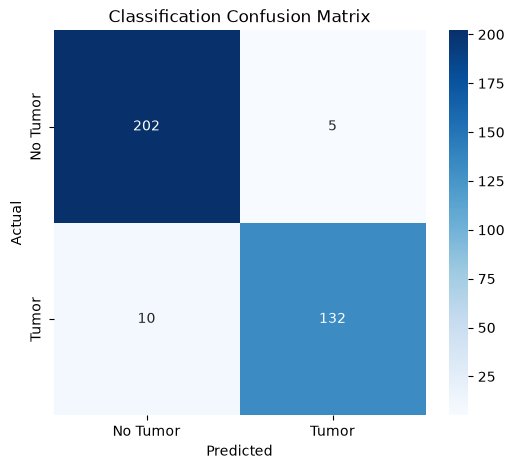

In [3]:
print("Evaluating Classification Ensemble...")
acc, f1, auc, cm, report = evaluate_classification(clf_ens, test_loader, DEVICE)

print(f"\nAccuracy: {acc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC:  {auc:.4f}\n")
print("Classification Report:")
print(report)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Tumor', 'Tumor'], yticklabels=['No Tumor', 'Tumor'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Classification Confusion Matrix')
plt.show()

## 3. Segmentation Evaluation
Next, we evaluate the segmentation ensemble to see how accurately it draws the boundaries for slices that actually contain tumors.

In [4]:
print("Evaluating Segmentation Ensemble...")
dice, iou = evaluate_segmentation(seg_ens, test_loader, DEVICE)

print(f"\nAverage Dice Score: {dice:.4f}")
print(f"Average IoU Score:  {iou:.4f}")

Evaluating Segmentation Ensemble...


Eval Segmentation:   0%|          | 0/22 [00:00<?, ?it/s]

Eval Segmentation:   5%|▍         | 1/22 [00:01<00:21,  1.02s/it]

Eval Segmentation:   9%|▉         | 2/22 [00:01<00:19,  1.03it/s]

Eval Segmentation:  14%|█▎        | 3/22 [00:02<00:16,  1.13it/s]

Eval Segmentation:  18%|█▊        | 4/22 [00:03<00:15,  1.16it/s]

... (14 outputs left out)

Eval Segmentation:  91%|█████████ | 20/22 [00:10<00:00,  2.36it/s]

Eval Segmentation: 100%|██████████| 22/22 [00:11<00:00,  3.85it/s]

Eval Segmentation: 100%|██████████| 22/22 [00:11<00:00,  1.98it/s]


Average Dice Score: 0.8833
Average IoU Score:  0.7953


## 4. Explainable AI (XAI)
Let's look under the hood! We will pick a specific image that contains a tumor and run our XAI pipeline on it to visualize:
1. **Grad-CAM**: Where the classifiers focus their attention.
2. **Agreement Maps**: Where the different segmentation models agree or disagree on the boundaries.
3. **Uncertainty Maps**: Monte-Carlo Dropout uncertainty.

Running XAI for TCGA_CS_4941_19960909_11.tif...


Maps generated!



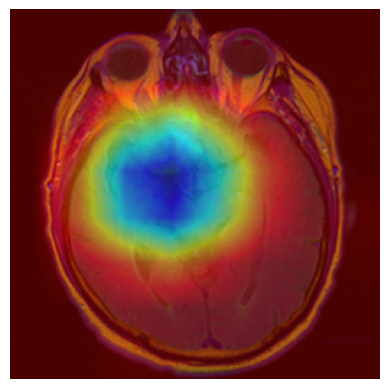

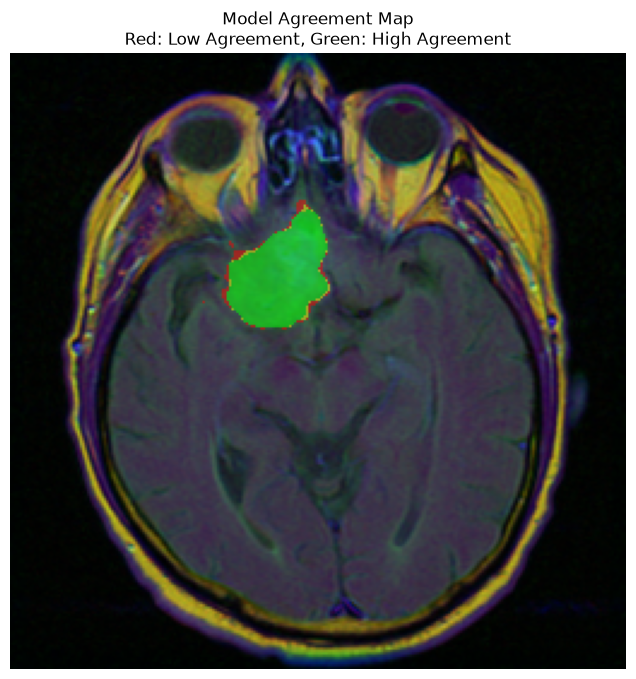

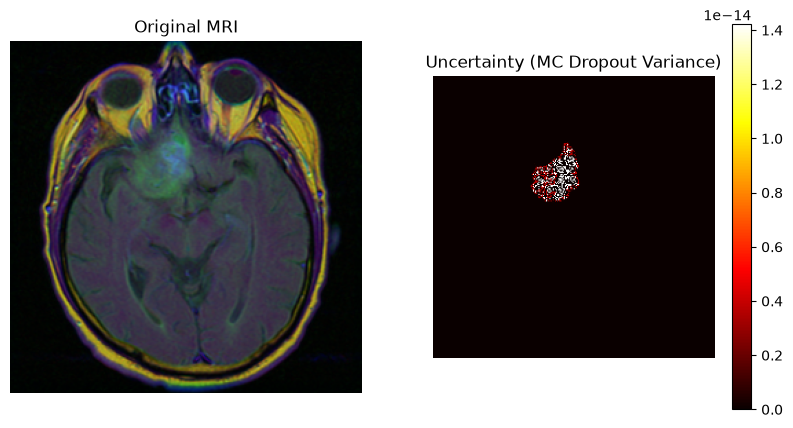

In [5]:
from src.explainability.compare import generate_full_explanation

# Pick a sample test image with a tumor
test_image_path = 'kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_11.tif'
save_directory = 'results/xai_notebook'

print(f"Running XAI for {os.path.basename(test_image_path)}...")
generate_full_explanation(test_image_path, clf_ens, seg_ens, DEVICE, save_directory)
print("Maps generated!\n")

base = os.path.basename(test_image_path).replace('.tif', '')

display(Image(filename=os.path.join(save_directory, f'{base}_gradcam.png')))
display(Image(filename=os.path.join(save_directory, f'{base}_agreement.png')))
display(Image(filename=os.path.join(save_directory, f'{base}_uncertainty.png')))